# 导数到底有什么用？手推泰勒：放大到最后，曲线都是直线

配套《手推到狗跑》视频。先在练习单上手推，再用这里的代码核对：

1. 割线斜率怎么趋近导数；
2. sinθ ≈ θ 能用到多大的角度；
3. Lite3 前腿的雅可比：手推的公式和数值差分对一对；
4. 直线（一阶泰勒）预测在多大角度失效；
5. 差分步长不是越小越好；
6. MuJoCo 里的“射门”。

从上往下依次运行每一格。前五节只要 numpy，最后一节要 mujoco。

## 检查环境（先运行这一格）

报 `No module named ...` 时运行这一格就行：它会把缺的包装进你当前选中的内核。

In [1]:
# 第一次运行：检查需要的包，缺哪个就装进当前这个内核（已经装过的直接跳过）
import importlib.util
need = [p for p in ['numpy', 'matplotlib', 'mujoco'] if importlib.util.find_spec(p) is None]
if need:
    get_ipython().run_line_magic('pip', 'install ' + ' '.join(need))
    need = [p for p in need if importlib.util.find_spec(p) is None]
print('环境就绪' if not need else '还缺：' + ', '.join(need) + '（看上面 pip 的报错，或换一个 Python 内核）')


环境就绪


## 仿真代码（先运行这一格）

和同文件夹的 `sim.py` 内容相同，放在这里是为了让 notebook 单独也能运行（踢球那一格要 mujoco，缺的 `lite3/` 模型会自动从配套仓库下载）。

In [2]:
"""导数到底有什么用：Lite3 单腿的正运动学、雅可比（手推 vs 数值差分）、线性预测为什么只在附近准。

    foot(h, k)          髋角 h、膝角 k → 脚心相对髋轴的位置 (x 向前, z 向上)，单位 m
    jac(h, k)           手推的雅可比：一阶泰勒展开的“斜率矩阵”
    jac_num(h, k, step) 数值差分算的雅可比（前向或中心）
    predict(h, k, dh, dk)  一阶泰勒（直线）预测：foot + J·[dh, dk]
    kick()              MuJoCo：狗架在检修架上，前右腿髋关节转 60° “射门”，球放在直线预测的落点

角度一律弧度；屏幕上讲的“度”只在打印时换算。
模型：DeepRoboticsLab/deep_robotics_model 的 Lite3 MJCF（BSD-3-Clause）。参数为教学设置，不代表实机。
运行环境：前半部分只要 numpy；kick() 要 mujoco（conda 环境 teaching-mujoco，mujoco 3.16）。
直接运行本文件 = 打印本期用到的主要数字。
"""
from pathlib import Path

import numpy as np

try:
    _HERE = Path(__file__).resolve().parent
except NameError:                  # 在 notebook 格子里运行时没有 __file__
    _HERE = Path.cwd()

# ---------------- 腿的几何（和 Lite3.xml 一致）----------------
L1 = 0.20                  # 大腿：髋轴 → 膝轴（m）
L2 = 0.21012               # 小腿：膝轴 → 脚心（m）
STAND = (-0.8, 1.6)        # 站姿（髋, 膝），弧度；髋角增大 = 脚往前，膝盖朝后
HIP_X = 0.1745             # 前腿髋轴在机身坐标里的位置（m）
HIP_Y = -(0.062 + 0.09735)   # 前右腿在机身右侧（y < 0）
FOOT_R = 0.022             # 脚球半径（m）


def foot(h, k):
    """正运动学：x = L1·sin h + L2·sin(h+k)，z = −L1·cos h − L2·cos(h+k)。"""
    return np.array([L1 * np.sin(h) + L2 * np.sin(h + k),
                     -L1 * np.cos(h) - L2 * np.cos(h + k)])


def jac(h, k):
    """手推的雅可比：每一列 = 只动一个关节时，脚往哪走、走多快（m/rad）。"""
    c1, c12 = np.cos(h), np.cos(h + k)
    s1, s12 = np.sin(h), np.sin(h + k)
    return np.array([[L1 * c1 + L2 * c12, L2 * c12],
                     [L1 * s1 + L2 * s12, L2 * s12]])


def jac_num(h, k, step=1e-6, kind="central"):
    """数值差分：每次只拨动一个关节 step 弧度，看脚动了多少。"""
    q = np.array([h, k], float)
    J = np.zeros((2, 2))
    for j in range(2):
        e = np.zeros(2)
        e[j] = step
        if kind == "central":
            J[:, j] = (foot(*(q + e)) - foot(*(q - e))) / (2 * step)
        else:
            J[:, j] = (foot(*(q + e)) - foot(*q)) / step
    return J


def predict(h, k, dh, dk=0.0):
    """一阶泰勒：在 (h, k) 附近，把脚的位置当成关节角的直线函数。"""
    return foot(h, k) + jac(h, k) @ np.array([dh, dk])


def miss(dh_deg, dk_deg=0.0, q0=STAND):
    """直线预测和真实位置差多少（m）。"""
    dh, dk = np.radians(dh_deg), np.radians(dk_deg)
    return float(np.linalg.norm(predict(*q0, dh, dk) - foot(q0[0] + dh, q0[1] + dk)))


# ---------------- 一元：sinθ ≈ θ ----------------
def sin_rel_err(theta):
    """用 θ 代替 sinθ 的相对误差：(θ − sinθ) / sinθ。"""
    return (theta - np.sin(theta)) / np.sin(theta)


def theta_for_err(e):
    """相对误差刚好等于 e 的角度（弧度），二分法。"""
    lo, hi = 1e-6, 1.5
    for _ in range(80):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if sin_rel_err(mid) < e else (lo, mid)
    return (lo + hi) / 2


# ---------------- 数值差分：步长越小越准吗？----------------
def diff_errors(hs, f=np.sin, df=np.cos, x=1.0):
    """前向、中心差分在不同步长下的误差（绝对值）。"""
    hs = np.asarray(hs, float)
    fwd = np.abs((f(x + hs) - f(x)) / hs - df(x))
    cen = np.abs((f(x + hs) - f(x - hs)) / (2 * hs) - df(x))
    return fwd, cen


# ---------------- MuJoCo：架在检修架上“射门” ----------------
MJCF = next((p for p in [_HERE / "lite3", _HERE.parents[1] / "assets" / "deep_robotics_model-main" / "Lite3" / "mjcf"]
             if (p / "Lite3.xml").exists()), _HERE / "lite3")
LITE3_FILES = ["Lite3.xml", "LICENSE.txt"] + [f"meshes/{n}.STL" for n in ("torso", "hip", "thigh", "shank")]
LITE3_URLS = ["https://gitee.com/nononodoubt/shoutui-daogoupao/raw/main/四足/一只狗怎么站起来/lite3/",
              "https://fastly.jsdelivr.net/gh/NONONODOUBT/shoutui-daogoupao@main/四足/一只狗怎么站起来/lite3/",
              "https://raw.githubusercontent.com/NONONODOUBT/shoutui-daogoupao/main/四足/一只狗怎么站起来/lite3/"]
DT = 0.001                 # 物理步长 1 ms
KP, KD, TAU_MAX = 60.0, 1.5, 30.0
CLEAR = 0.012              # 站姿时脚底离地面的空隙（m）：狗是架空的
BALL_R = 0.033             # 网球半径（m）
KICK_LEG = 1               # 关节顺序 FL FR HL HR：踢球的是前右腿（侧面镜头里狗朝右）
KICK_DEG = 60.0            # 可皮算的：想往前 30 cm，1° 走 0.5 cm → 60°
KICK_T0, KICK_RAMP = 1.0, 0.35


def download_lite3(dst):
    """只拿到 notebook、旁边没有 lite3/ 时，从配套仓库下载模型（约 3 MB，国内先走 Gitee）。"""
    from urllib.parse import quote
    from urllib.request import urlopen
    for base in LITE3_URLS:
        try:
            for f in LITE3_FILES:
                data = urlopen(quote(base + f, safe=":/@"), timeout=30).read()
                (dst / f).parent.mkdir(parents=True, exist_ok=True)
                (dst / f).write_bytes(data)
            print(f"已下载 Lite3 模型到 {dst}")
            return
        except OSError as e:
            print(f"从 {base.split('/')[2]} 下载失败（{e}），换一个地址")
    raise FileNotFoundError(f"找不到 Lite3 模型：请把配套仓库里的 lite3/ 文件夹放到 {dst.parent}")


def torso_height():
    """机身高度：站姿脚底离地 CLEAR。"""
    return -foot(*STAND)[1] + FOOT_R + CLEAR


def ball_pos():
    """球放在直线预测的落点正下方的地面上（世界坐标，机身在原点上方）。"""
    x = HIP_X + predict(*STAND, np.radians(KICK_DEG))[0]
    return np.array([x, HIP_Y, BALL_R])


def load_model():
    """机身焊死在检修架上（去掉自由关节），地上放一个网球。
    MuJoCo 在 Windows 上打不开中文路径：自己读 XML 和网格，以内容形式传进去。"""
    import mujoco
    if not (MJCF / "Lite3.xml").exists():
        download_lite3(MJCF)
    xml = (MJCF / "Lite3.xml").read_text(encoding="utf-8")
    assets = {f"./meshes/{p.name}": p.read_bytes() for p in (MJCF / "meshes").iterdir()}
    spec = mujoco.MjSpec.from_string(xml, assets)
    spec.assets = {k[2:]: v for k, v in assets.items()}
    torso = spec.body("TORSO")
    spec.delete(spec.joint("floating_base"))
    torso.pos = [0, 0, torso_height()]
    # 检修架：一根立柱 + 托板（只是画面，不参与碰撞）
    stand = spec.worldbody.add_body(name="stand")
    grey = [0.30, 0.33, 0.38, 1]
    stand.add_geom(type=mujoco.mjtGeom.mjGEOM_BOX, size=[0.03, 0.03, torso_height() / 2 - 0.03],
                   pos=[-0.05, 0, torso_height() / 2 - 0.03], rgba=grey, contype=0, conaffinity=0)
    stand.add_geom(type=mujoco.mjtGeom.mjGEOM_BOX, size=[0.16, 0.16, 0.012], pos=[-0.05, 0, 0.012],
                   rgba=grey, contype=0, conaffinity=0)
    ball = spec.worldbody.add_body(name="ball", pos=ball_pos().tolist())
    ball.add_freejoint()
    ball.add_geom(type=mujoco.mjtGeom.mjGEOM_SPHERE, size=[BALL_R, 0, 0], mass=0.058,
                  rgba=[0.86, 0.93, 0.25, 1], contype=1, conaffinity=1, friction=[0.8, 0.02, 0.002])
    spec.add_texture(name="sky", type=mujoco.mjtTexture.mjTEXTURE_SKYBOX, builtin=mujoco.mjtBuiltin.mjBUILTIN_GRADIENT,
                     rgb1=[0.62, 0.76, 0.92], rgb2=[0.09, 0.13, 0.23], width=512, height=3072)
    for t in spec.textures:
        if t.name == "checker":
            t.rgb1, t.rgb2 = [0.70, 0.75, 0.82], [0.86, 0.89, 0.93]
    m = spec.compile()
    m.opt.timestep = DT
    m.vis.global_.offwidth, m.vis.global_.offheight = 1920, 1080
    dog = (m.geom_bodyid > 0) & (m.geom_group == 2) & (m.geom_matid < 0)
    m.geom_rgba[dog] = [0.58, 0.60, 0.64, 1]
    return m


def kick(m=None, deg=KICK_DEG, T=2.5, fps=60, traj=None):
    """前右腿髋关节在 KICK_RAMP 秒内转 deg 度，其他关节锁在站姿。
    返回 dict：时间、脚心（相对髋轴）轨迹、球的位置；traj 传 list 时按 fps 存 qpos 供渲染。"""
    import mujoco
    m = m or load_model()
    d = mujoco.MjData(m)
    q_stand = np.tile([0.0, *STAND], 4)
    d.qpos[:12] = q_stand
    mujoco.mj_forward(m, d)
    fid = mujoco.mj_name2id(m, mujoco.mjtObj.mjOBJ_BODY, "FR_FOOT")
    tid = mujoco.mj_name2id(m, mujoco.mjtObj.mjOBJ_BODY, "FR_THIGH")
    bid = mujoco.mj_name2id(m, mujoco.mjtObj.mjOBJ_BODY, "ball")
    n = int(T / DT)
    log = {k: [] for k in ["t", "hip", "foot_x", "foot_z", "ball_x", "ball_z", "min_gap"]}
    for i in range(n):
        t = i * DT
        q_ref = q_stand.copy()
        s = np.clip((t - KICK_T0) / KICK_RAMP, 0, 1)
        q_ref[3 * KICK_LEG + 1] += np.radians(deg) * (3 * s ** 2 - 2 * s ** 3)      # 平滑地转过去
        tau = KP * (q_ref - d.qpos[:12]) - KD * d.qvel[:12]
        d.ctrl[:] = np.clip(tau, -TAU_MAX, TAU_MAX)
        mujoco.mj_step(m, d)
        rel = d.xpos[fid] - d.xpos[tid]                               # 脚心相对髋（大腿）轴
        log["t"].append(t)
        log["hip"].append(d.qpos[3 * KICK_LEG + 1])
        log["foot_x"].append(rel[0])
        log["foot_z"].append(rel[2])
        log["ball_x"].append(d.xpos[bid][0])
        log["ball_z"].append(d.xpos[bid][2])
        log["min_gap"].append(np.linalg.norm(d.xpos[fid] - d.xpos[bid]) - FOOT_R - BALL_R)
        if traj is not None and int(t * fps) >= len(traj):
            traj.append(d.qpos.copy())
    return {k: np.array(v) for k, v in log.items()}


In [3]:
from sim import *

## 准备工作

设置中文字体（不设的话图里的中文会变成方框）。

In [4]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'PingFang SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

## 1. 割线 → 切线

y = x² 在 x = 1 处，割线斜率是 2 + h。h 越小，越接近 2。

In [5]:
for h in [1, 0.5, 0.1, 0.01, 0.001]:
    print(f'h = {h:<6}  割线斜率 = {((1 + h) ** 2 - 1) / h:.6f}')

h = 1       割线斜率 = 3.000000
h = 0.5     割线斜率 = 2.500000
h = 0.1     割线斜率 = 2.100000
h = 0.01    割线斜率 = 2.010000
h = 0.001   割线斜率 = 2.001000


## 2. sinθ ≈ θ 能用到多大的角度

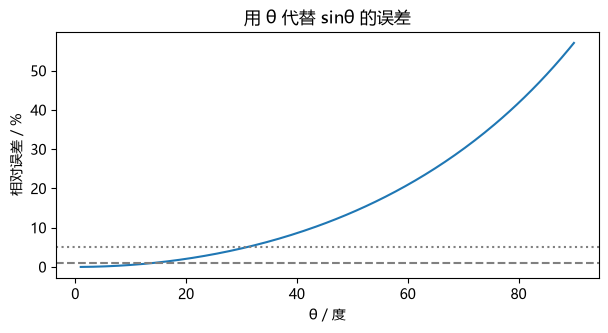

误差 ≤ 1%：θ ≤ 14.0°
误差 ≤ 5%：θ ≤ 30.8°


In [6]:
deg = np.linspace(1, 90, 200)
err = sin_rel_err(np.radians(deg)) * 100
plt.figure(figsize=(7, 3.2)); plt.plot(deg, err)
plt.axhline(1, ls='--', c='gray'); plt.axhline(5, ls=':', c='gray')
plt.xlabel('θ / 度'); plt.ylabel('相对误差 / %'); plt.title('用 θ 代替 sinθ 的误差'); plt.show()
for e in (0.01, 0.05):
    print(f'误差 ≤ {e:.0%}：θ ≤ {np.degrees(theta_for_err(e)):.1f}°')

## 3. 狗腿的雅可比：手推 vs 数值差分

`jac` 是视频里手推的四个偏导；`jac_num` 每次只拨动一个关节一点点，看脚动了多少。

In [7]:
h0, k0 = STAND
print('手推：\n', jac(h0, k0).round(4))
print('中心差分：\n', jac_num(h0, k0).round(4))
print('最大相差：', np.abs(jac(h0, k0) - jac_num(h0, k0)).max())
print(f'髋转 1°，脚往前 {jac(h0, k0)[0, 0] * np.radians(1) * 100:.2f} cm')

手推：
 [[0.2857 0.1464]
 [0.0073 0.1507]]
中心差分：
 [[0.2857 0.1464]
 [0.0073 0.1507]]
最大相差： 2.7773366939598532e-11
髋转 1°，脚往前 0.50 cm


## 4. 直线预测什么时候失效

膝不动、只转髋：真实的脚走圆弧（半径 = 髋轴到脚尖的距离），一阶泰勒给的是切线。

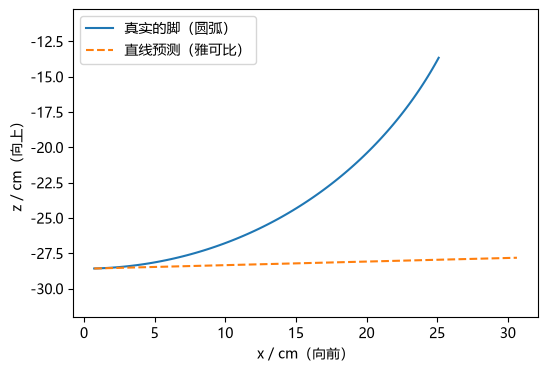

髋转  1°：直线预测差 0.00 cm
髋转 10°：直线预测差 0.43 cm
髋转 30°：直线预测差 3.89 cm
髋转 60°：直线预测差 15.20 cm


In [8]:
a = np.radians(np.linspace(0, 60, 100))
real = np.array([foot(h0 + x, k0) for x in a]) * 100
pred = np.array([predict(h0, k0, x) for x in a]) * 100
plt.figure(figsize=(6, 4)); plt.plot(real[:, 0], real[:, 1], label='真实的脚（圆弧）')
plt.plot(pred[:, 0], pred[:, 1], '--', label='直线预测（雅可比）')
plt.axis('equal'); plt.xlabel('x / cm（向前）'); plt.ylabel('z / cm（向上）'); plt.legend(); plt.show()
for d in (1, 10, 30, 60):
    print(f'髋转 {d:>2}°：直线预测差 {miss(d) * 100:.2f} cm')

## 5. 步长越小越准吗？

对 sin 在 x = 1 处做差分，h 从 10⁻¹ 缩到 10⁻¹⁶。

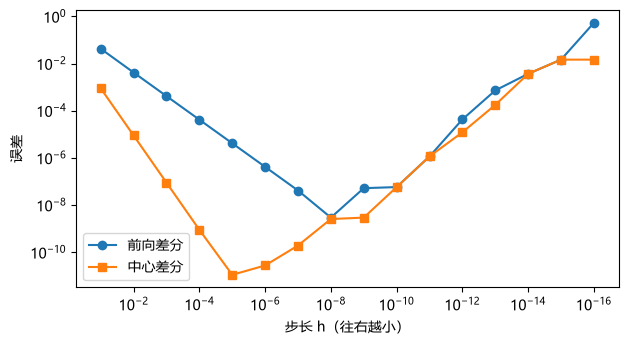

前向最好的 h： 1e-08   中心最好的 h： 1e-05


In [9]:
hs = 10.0 ** -np.arange(1, 17)
fwd, cen = diff_errors(hs)
plt.figure(figsize=(7, 3.6)); plt.loglog(hs, fwd, 'o-', label='前向差分'); plt.loglog(hs, cen, 's-', label='中心差分')
plt.gca().invert_xaxis(); plt.xlabel('步长 h（往右越小）'); plt.ylabel('误差'); plt.legend(); plt.show()
print('前向最好的 h：', hs[np.argmin(fwd)], '  中心最好的 h：', hs[np.argmin(cen)])

## 6. MuJoCo 里的“射门”

狗架在检修架上，前右腿髋关节转 60°，球放在直线预测的落点。下面比较 MuJoCo 里测到的脚尖位置和手推公式。

In [10]:
k = kick()
print('MuJoCo 脚尖（相对髋轴）：', np.round([k['foot_x'][-1], k['foot_z'][-1]], 4))
print('手推正运动学：           ', foot(h0 + np.radians(60), k0).round(4))
print('球被碰到了吗？', '碰到了' if np.abs(k['ball_x'] - k['ball_x'][0]).max() > 1e-4 else '一动没动',
      f'（脚和球最近 {k["min_gap"].min() * 100:.1f} cm）')

MuJoCo 脚尖（相对髋轴）： [ 0.2506 -0.1386]
手推正运动学：            [ 0.2511 -0.1366]
球被碰到了吗？ 一动没动 （脚和球最近 7.8 cm）


## 作业

下面三格要你自己改、自己跑。

In [ ]:
# 作业 1：把你在练习单第 4 题手推的 J 填进来，和 jac(h0, k0) 对一对。
J_mine = np.array([[0.0, 0.0],
                   [0.0, 0.0]])


In [ ]:
# 作业 2：换一个站姿（比如 h0 = -0.6, k0 = 1.2），重画第 4 节的圆弧和切线。
# 误差 1 cm 以内，髋最多能转多少度？和站姿有关吗？


In [ ]:
# 作业 3：换一个函数（比如 np.exp 在 x = 1），重画第 5 节的 V 字。
# 最好的步长变了吗？用练习单第 5 题的公式 h* = 2·sqrt(ε·|f| / |f''|) 解释。
